# 02 · Time-based split and the training-window experiment

**Goal of this notebook**

1. Fix the scope (individual applications) and the out-of-time year (2017).
2. Choose the training window **by experiment**, on a separate validation slice (H2 2016),
   without looking at the out-of-time year.
3. Build the final train / test / out-of-time samples and save them to `data/processed/`.

**Why a window experiment.** A PD model must work on *future* borrowers. Older data adds
history and defaults, but the borrower mix and Lending Club's credit policy change over time,
and 14 bureau fields only exist from 2016. Whether more history or fresher data wins is an
empirical question, so it is tested rather than assumed.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

from src.data import TARGET, TARGET_LIFETIME, load_interim, make_modelling_base
from src.features_config import (CANDIDATE, LENDER_SCORE, PROXY, KEY, JOINT_ONLY, NEW_IN_2016,
                                  assert_no_leakage)
from src.split import (OOT, WINDOW_VALIDATION, CANDIDATE_WINDOWS, TRAIN_END, SEED, CHOSEN_WINDOW,
                       CHOSEN_FEATURE_SET, PROCESSED_PATH, select_scope, issued_between,
                       shift_to_end, final_split)

FIG = ROOT / "reports" / "figures"
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50, "display.width", 140)

def save(fig, name):
    fig.savefig(FIG / f"02_{name}.png", dpi=120, bbox_inches="tight")

def gini(y, p):
    return 2 * roc_auc_score(y, p) - 1

## 1. Scope

In [2]:
base = make_modelling_base(load_interim())
print(f"Modelling base: {len(base):,} loans")
base = select_scope(base)
print(f"Individual applications: {len(base):,} loans, 12-month default rate {base[TARGET].mean():.2%}")

# Credit history length at origination, in months. The raw date itself is not a feature.
base["credit_hist_months"] = ((base["issue_d"].dt.year - base["earliest_cr_line"].dt.year) * 12
                              + base["issue_d"].dt.month - base["earliest_cr_line"].dt.month)

Modelling base: 1,256,806 loans


Individual applications: 1,227,414 loans, 12-month default rate 3.75%


## 2. Time slices

| Slice | Issued | Role |
|---|---|---|
| Training-window candidates | 2013-01 … 2016-06 | the model learns here |
| Validation slice | 2016-07 … 2016-12 | windows are compared here |
| Out-of-time | 2017-01 … 2017-12 | **not used** in this experiment |

In [3]:
slices = {**{f"window: {k}": v for k, v in CANDIDATE_WINDOWS.items()},
          "validation slice": WINDOW_VALIDATION, "out-of-time": OOT}
pd.DataFrame({
    name: {"from": w[0], "to": w[1], "loans": int(issued_between(base, w).sum()),
           "bads": int(base.loc[issued_between(base, w), TARGET].sum()),
           "default_rate": base.loc[issued_between(base, w), TARGET].mean().round(4)}
    for name, w in slices.items()
}).T

,from,to,loans,bads,default_rate
window: H1 2016,2016-01,2016-06,168258,7340,0.0436
window: 2015 - H1 2016,2015-01,2016-06,451192,17386,0.0385
window: 2013 - H1 2016,2013-01,2016-06,714184,24990,0.035
validation slice,2016-07,2016-12,150019,6716,0.0448
out-of-time,2017-01,2017-12,296484,11978,0.0404


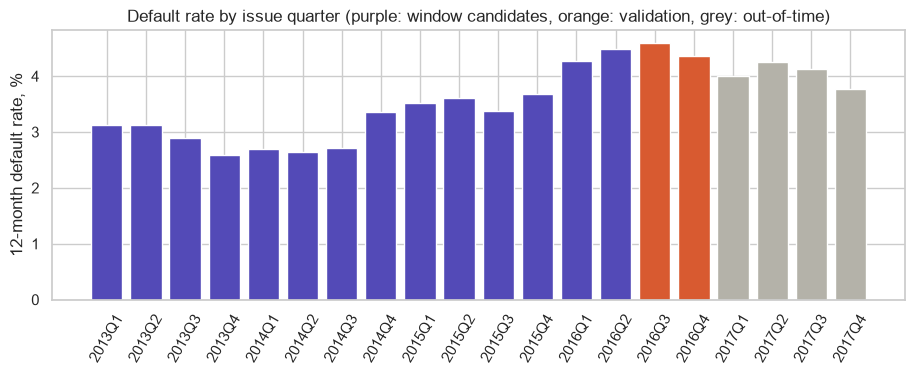

In [4]:
q = base.groupby(base["issue_d"].dt.to_period("Q"))[TARGET].agg(loans="size", default_rate="mean")
q = q.loc["2013Q1":]
fig, ax = plt.subplots(figsize=(11, 3.5))
colors = ["#534AB7" if p < pd.Period("2016Q3") else "#D85A30" if p < pd.Period("2017Q1") else "#B4B2A9"
          for p in q.index]
ax.bar(q.index.astype(str), q["default_rate"] * 100, color=colors)
ax.set_ylabel("12-month default rate, %")
ax.set_title("Default rate by issue quarter (purple: window candidates, orange: validation, grey: out-of-time)")
ax.tick_params(axis="x", rotation=60)
save(fig, "dr_by_quarter")
plt.show()

## 3. Features for the experiment

The experiment needs a quick, reasonable model, not the final one. LightGBM with fixed
settings is used because it handles missing values and raw (unbinned) features, so every
window is treated identically without any tuning.

Two feature sets:

* **base**: candidate features available since 2012 Q4;
* **full**: base + the 14 bureau fields that appear in Q1 2016.

In a window that starts before 2016 the new fields are empty for older loans, so the model
can learn "missing = older loan". The experiment shows whether this hurts.

In [5]:
CAT = ["purpose", "home_ownership", "verification_status", "emp_length",
       "initial_list_status", "disbursement_method"]
excluded = set(JOINT_ONLY) | set(NEW_IN_2016) | {"application_type", "earliest_cr_line"}
FEATURES = {
    "base": [c for c in CANDIDATE if c not in excluded] + ["credit_hist_months"],
}
FEATURES["full"] = FEATURES["base"] + NEW_IN_2016
for f in FEATURES.values():
    assert_no_leakage(f)
print({k: len(v) for k, v in FEATURES.items()})

for c in CAT:  # same category codes in every slice
    base[c] = base[c].astype("category")

{'base': 64, 'full': 78}


## 4. The experiment

**Decision rule, fixed before the run.** The window with the highest Gini on the validation
slice wins. If its advantage over a longer window is not significant (the 95% bootstrap
interval of the Gini difference contains zero), the longer window is preferred: more defaults
give more stable WoE bins and the model sees more of the credit cycle.

Each model uses a random 10% of its own window for early stopping, so the validation slice
is never used for fitting.

In [6]:
PARAMS = dict(n_estimators=3000, learning_rate=0.05, num_leaves=31, min_child_samples=200,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
              random_state=SEED, verbose=-1)

val = base[issued_between(base, WINDOW_VALIDATION)]
runs, preds = [], {}
for wname, window in CANDIDATE_WINDOWS.items():
    tr_all = base[issued_between(base, window)]
    tr, es = train_test_split(tr_all, test_size=0.1, stratify=tr_all[TARGET], random_state=SEED)
    for fname, feats in FEATURES.items():
        model = lgb.LGBMClassifier(**PARAMS)
        model.fit(tr[feats], tr[TARGET], eval_X=(es[feats],), eval_y=(es[TARGET],), eval_metric="auc",
                  callbacks=[lgb.early_stopping(100, verbose=False)])
        p = model.predict_proba(val[feats])[:, 1]
        key = (wname, fname)
        preds[key] = p
        runs.append({
            "window": wname, "features": fname, "train_loans": len(tr_all),
            "train_bads": int(tr_all[TARGET].sum()), "train_dr": tr_all[TARGET].mean(),
            "trees": model.best_iteration_,
            "gini_validation": gini(val[TARGET], p),
            "mean_pd_validation": p.mean(), "dr_validation": val[TARGET].mean(),
        })
res = pd.DataFrame(runs).set_index(["window", "features"])
res.round(4)

train_loans  train_bads  train_dr  trees  gini_validation  mean_pd_validation  dr_validation
window         features                                                                                              
H1 2016        base           168258        7340    0.0436    164           0.3772              0.0431         0.0448
               full           168258        7340    0.0436    199           0.3872              0.0424         0.0448
2015 - H1 2016 base           451192       17386    0.0385    172           0.3899              0.0379         0.0448
               full           451192       17386    0.0385    190           0.3986              0.0426         0.0448
2013 - H1 2016 base           714184       24990    0.0350    454           0.3955              0.0355         0.0448
               full           714184       24990    0.0350    373           0.4019              0.0424         0.0448

### 4.1 Is the difference real? Paired bootstrap on the validation slice

The same resampled validation loans are scored by every model, so the Gini *difference*
is measured on identical data. 300 resamples.

In [7]:
rng = np.random.default_rng(SEED)
y = val[TARGET].to_numpy()
best = res["gini_validation"].idxmax()
boot = {k: [] for k in preds}
for _ in range(300):
    i = rng.integers(0, len(y), len(y))
    for k, p in preds.items():
        boot[k].append(gini(y[i], p[i]))
boot = pd.DataFrame(boot)
diff = boot.sub(boot[best], axis=0)
res["gini_ci_low"] = boot.quantile(0.025).values
res["gini_ci_high"] = boot.quantile(0.975).values
res["diff_vs_best"] = diff.mean().values
res["diff_ci_low"] = diff.quantile(0.025).values
res["diff_ci_high"] = diff.quantile(0.975).values
res["significantly_worse"] = res["diff_ci_high"] < 0
print("Best:", best)
res[["train_loans", "gini_validation", "gini_ci_low", "gini_ci_high",
     "diff_vs_best", "diff_ci_low", "diff_ci_high", "significantly_worse"]].round(4)

Best: ('2013 - H1 2016', 'full')


train_loans  gini_validation  gini_ci_low  gini_ci_high  diff_vs_best  diff_ci_low  diff_ci_high  \
window         features                                                                                                     
H1 2016        base           168258           0.3772       0.3660        0.3883       -0.0247      -0.0303       -0.0184   
               full           168258           0.3872       0.3764        0.3985       -0.0148      -0.0202       -0.0095   
2015 - H1 2016 base           451192           0.3899       0.3784        0.4011       -0.0120      -0.0174       -0.0071   
               full           451192           0.3986       0.3873        0.4099       -0.0032      -0.0074        0.0004   
2013 - H1 2016 base           714184           0.3955       0.3845        0.4065       -0.0065      -0.0112       -0.0021   
               full           714184           0.4019       0.3906        0.4128        0.0000       0.0000        0.0000   

                         significantly_worse  
window         features                       
H1 2016        base                     True  
               full                     True  
2015 - H1 2016 base                     True  
               full                    False  
2013 - H1 2016 base                     True  
               full                    False

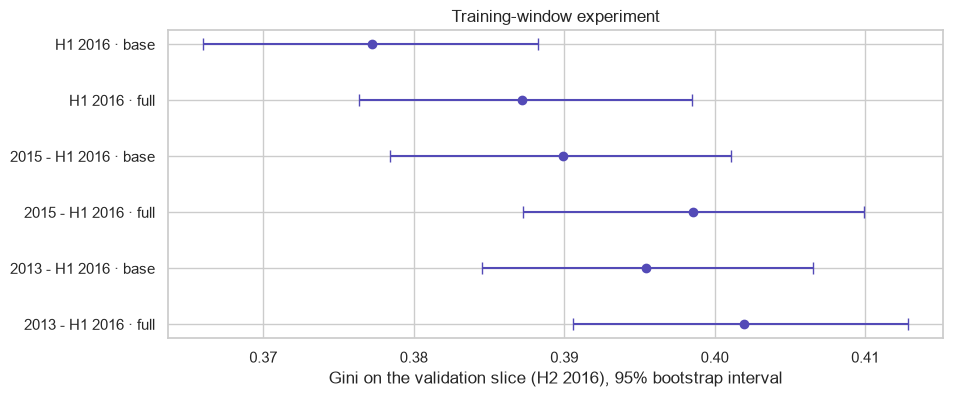

In [8]:
r = res.reset_index()
fig, ax = plt.subplots(figsize=(10, 4))
pos = np.arange(len(r))
ax.errorbar(r["gini_validation"], pos,
            xerr=[r["gini_validation"] - r["gini_ci_low"], r["gini_ci_high"] - r["gini_validation"]],
            fmt="o", color="#534AB7", capsize=4)
ax.set_yticks(pos)
ax.set_yticklabels(r["window"] + " · " + r["features"])
ax.invert_yaxis()
ax.set_xlabel("Gini on the validation slice (H2 2016), 95% bootstrap interval")
ax.set_title("Training-window experiment")
save(fig, "window_experiment")
plt.show()

In [9]:
# Gini by month of the validation slice: is the ranking consistent, not driven by one month?
month = val["issue_d"].dt.to_period("M")
by_month = pd.DataFrame({f"{w} · {f}": pd.Series(p, index=val.index).groupby(month).apply(
    lambda s: gini(val.loc[s.index, TARGET], s)) for (w, f), p in preds.items()}).T
by_month.round(3)

issue_d,2016-07,2016-08,2016-09,2016-10,2016-11,2016-12
H1 2016 · base,0.389,0.377,0.388,0.367,0.383,0.359
H1 2016 · full,0.396,0.392,0.396,0.376,0.400,0.363
2015 - H1 2016 · base,0.406,0.380,0.406,0.389,0.397,0.366
2015 - H1 2016 · full,0.420,0.393,0.414,0.389,0.403,0.375
2013 - H1 2016 · base,0.419,0.395,0.407,0.384,0.398,0.371
2013 - H1 2016 · full,0.427,0.402,0.410,0.392,0.406,0.376


## 5. Final split

The chosen window keeps its length and is shifted to end in December 2016, so the most
recent pre-out-of-time loans (the validation slice) also train the model. A random,
stratified 20% of the window is held out as **test**, to detect overfitting. The
out-of-time year 2017 is untouched until notebook 05.

In [10]:
assert res["gini_validation"].idxmax() == (CHOSEN_WINDOW, CHOSEN_FEATURE_SET),     "experiment result differs from the decision recorded in src/split.py"
train_window = shift_to_end(CANDIDATE_WINDOWS[CHOSEN_WINDOW])
print("Chosen:", CHOSEN_WINDOW, "/", CHOSEN_FEATURE_SET, "-> final training window", train_window)

samples = final_split(base, train_window)
summary = samples.groupby("sample").agg(
    issued_from=("issue_d", "min"), issued_to=("issue_d", "max"), loans=(TARGET, "size"),
    bads=(TARGET, "sum"), default_rate=(TARGET, "mean")).loc[["train", "test", "oot"]]
summary["issued_from"] = summary["issued_from"].dt.strftime("%Y-%m")
summary["issued_to"] = summary["issued_to"].dt.strftime("%Y-%m")
summary.round(4)

Chosen: 2013 - H1 2016 / full -> final training window ('2013-07', '2016-12')


,issued_from,issued_to,loans,bads,default_rate
sample,,,,,
train,2013-07,2016-12,658463,24338,0.0370
test,2013-07,2016-12,164616,6084,0.0370
oot,2017-01,2017-12,296484,11978,0.0404


In [11]:
# No out-of-time loan may share an issue month with the development sample.
dev_months = set(samples.loc[samples["sample"] != "oot", "issue_d"])
oot_months = set(samples.loc[samples["sample"] == "oot", "issue_d"])
assert not dev_months & oot_months

# Saved columns: candidate features, benchmark and fairness columns, keys and targets.
# debt_settlement_flag is post-origination; it is kept only for the Part 2 sensitivity test.
features = FEATURES[CHOSEN_FEATURE_SET]
keep = (["id", "issue_d", "issue_year", "loan_status", "sample", TARGET, TARGET_LIFETIME]
        + features + list(LENDER_SCORE) + list(PROXY) + ["debt_settlement_flag"])
PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)
samples[keep].to_parquet(PROCESSED_PATH, index=False)
print(f"Saved {len(samples):,} rows x {len(keep)} columns to {PROCESSED_PATH.relative_to(ROOT)}")

Saved 1,119,563 rows x 94 columns to data\processed\samples.parquet


## 6. Conclusions

### Experiment result
| Window | Features | Train loans | Validation Gini (95% CI) | vs best |
|---|---|---|---|---|
| H1 2016 | base | 168k | 0.377 (0.366–0.388) | significantly worse |
| H1 2016 | full | 168k | 0.387 (0.376–0.399) | significantly worse |
| 2015 – H1 2016 | base | 451k | 0.390 (0.378–0.401) | significantly worse |
| 2015 – H1 2016 | full | 451k | 0.399 (0.387–0.410) | not significant (−0.003) |
| 2013 – H1 2016 | base | 714k | 0.396 (0.385–0.407) | significantly worse |
| **2013 – H1 2016** | **full** | **714k** | **0.402 (0.391–0.413)** | **best** |

- **More history wins.** Within each feature set, Gini grows with the window length. The longest
  window is also the best one, so the tie-break rule was not needed. It wins in every one of the
  six validation months, so the result is not driven by a single month.
- **The 2016 bureau fields help** (+0.006 to +0.010 Gini in every window), even in windows where
  they are empty for most loans.
- Gini 0.40 of a quick, untuned model is on the level of the Lending Club sub-grade benchmark
  (0.40): the final models have to add value over it, not just reach it.

### Final samples (`data/processed/samples.parquet`, 94 columns)
| Sample | Issued | Loans | Default rate |
|---|---|---|---|
| train | 2013-07 … 2016-12 | 658,463 | 3.70% |
| test (random 20%) | 2013-07 … 2016-12 | 164,616 | 3.70% |
| out-of-time | 2017-01 … 2017-12 | 296,484 | 4.04% |

The chosen 42-month window is shifted to end in December 2016, so the validation slice is now
part of training. The out-of-time year has not been used for any decision so far.

### Findings for Part 2 (validation)
- **Missingness of the 2016 fields acts as a period indicator.** These fields are empty for
  loans issued before 2016, which also had a lower default rate. With the full feature set the
  mean predicted PD on the validation slice is 4.24% against 3.55% with the base set (actual
  4.48%): part of the "help" from the new fields is the model recognising recent loans. In
  2017 all fields are filled, so every loan falls on the "recent" side. In WoE binning the
  missing bin of these fields must be reviewed, and its effect on out-of-time calibration
  tested.
- **Calibration drift:** the training default rate (3.70%) is below the out-of-time rate (4.04%).
  An under-prediction of PD in 2017 is expected and will need recalibration or a margin
  of conservatism.
- The window choice was made on one validation slice (H2 2016); the paired bootstrap shows
  the differences between the top two candidates are within noise.